# Sanity checks of the DeGroot model

## Setup

Load the baseline config and build the interaction network.

In [1]:
import sys
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

REPO_ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT))

from src import model
from src.config import load_config

config = load_config(REPO_ROOT / "configs" / "degroot_base.yaml")
model_params = config.model
network_graph, influence_matrix = model.build_network(config.network, np.random.default_rng(config.seed))
n_agents = config.network.n_agents

print(f"n_agents = {n_agents}, λ (self_weight) = {model_params.self_weight}")
print(f"σ_p = {model_params.process_noise_sd}, σ_e = {model_params.expression_noise_sd}, "
      f"σ_m = {model_params.measurement_noise_sd}")

n_agents = 50, λ (self_weight) = 0.3
σ_p = 0.05, σ_e = 0.05, σ_m = 0.1


Helper for the sanity checks below: `simulate_opinions` returns hidden opinions $x$ and expressions $s$ for $T$ steps, from initial opinions $x_0$ and influence matrix $W$. All checks share the same $x_0 \sim \mathcal U(0,1)$.

In [2]:
def simulate_opinions(model_params, influence_matrix, initial_opinions, n_steps, rng):
    """Simulate hidden opinions and expressions, each of shape (n_steps, n_agents)."""
    n_agents = initial_opinions.size
    opinions = np.empty((n_steps, n_agents))
    expressions = np.empty((n_steps, n_agents))
    opinions[0] = initial_opinions
    expressions[0] = model.express(initial_opinions, model_params, rng)
    for t in range(1, n_steps):
        opinions[t] = model.step(opinions[t - 1], expressions[t - 1], influence_matrix, model_params, rng)
        expressions[t] = model.express(opinions[t], model_params, rng)
    return opinions, expressions


initial_opinions = np.random.default_rng(123).uniform(0, 1, n_agents)

## Check 1 — Classical limit

With $\sigma_p = \sigma_e = 0$ we have $s = x$, so the update is classical DeGroot,
$x_t = A x_{t-1}$ with $A = \lambda I + (1-\lambda) W$. $A$ is row-stochastic and, on a connected
non-bipartite graph with $\lambda > 0$, primitive, so all opinions converge to the consensus
$\pi^\top x_0$, where $\pi$ is the left eigenvector of $A$ for eigenvalue 1, normalised to sum 1.
After 500 steps every agent should be within $10^{-6}$ of that value.

π·x0 = 0.484760
max_i |x_i,T − π·x0| = 8.20e-08


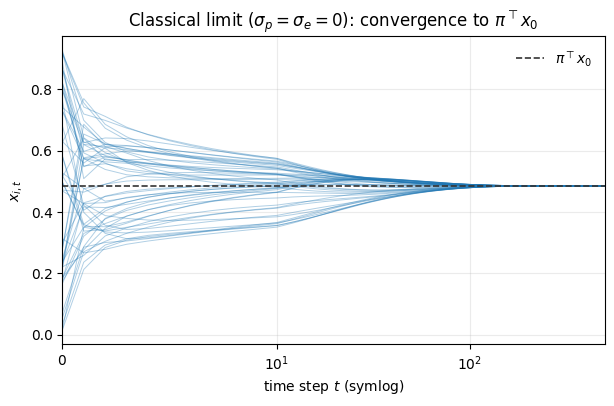

In [3]:
noise_free_params = replace(model_params, process_noise_sd=0.0, expression_noise_sd=0.0)
n_steps_to_consensus = 500
noise_free_opinions, _ = simulate_opinions(
    noise_free_params, influence_matrix, initial_opinions, n_steps_to_consensus, np.random.default_rng(0)
)

# Consensus predicted by theory: π·x0, with π the left eigenvector of A for eigenvalue 1.
self_weight = model_params.self_weight
update_matrix = self_weight * np.eye(n_agents) + (1 - self_weight) * influence_matrix
eigenvalues, eigenvectors = np.linalg.eig(update_matrix.T)
consensus_weights = np.real(eigenvectors[:, np.argmin(np.abs(eigenvalues - 1))])
consensus_weights /= consensus_weights.sum()
predicted_consensus = consensus_weights @ initial_opinions
max_deviation = np.max(np.abs(noise_free_opinions[-1] - predicted_consensus))

print(f"π·x0 = {predicted_consensus:.6f}")
print(f"max_i |x_i,T − π·x0| = {max_deviation:.2e}")
assert max_deviation < 1e-6

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(noise_free_opinions, color="C0", linewidth=0.7, alpha=0.35)
ax.axhline(predicted_consensus, color="0.2", linestyle="--", linewidth=1.2, label=r"$\pi^\top x_0$")
ax.set_xscale("symlog", linthresh=10)
ax.set_xlim(0, n_steps_to_consensus)
ax.set_xlabel(r"time step $t$ (symlog)")
ax.set_ylabel(r"$x_{i,t}$")
ax.set_title(r"Classical limit ($\sigma_p = \sigma_e = 0$): convergence to $\pi^\top x_0$")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
plt.show()

## Check 2 — Noise behaviour

With noise, opinions no longer reach exact consensus: they fluctuate around a drifting
near-consensus. The spread across agents, $\mathrm{std}_i(x_{i,t})$, should settle at a level
that grows with each noise source. We vary $\sigma_p$ with $\sigma_e = 0$, and $\sigma_e$ with
$\sigma_p = 0$, using the same random stream for every setting. With both at zero the spread
decays geometrically (a straight line on the log axis), at a rate set by the second-largest
eigenvalue of $A$.

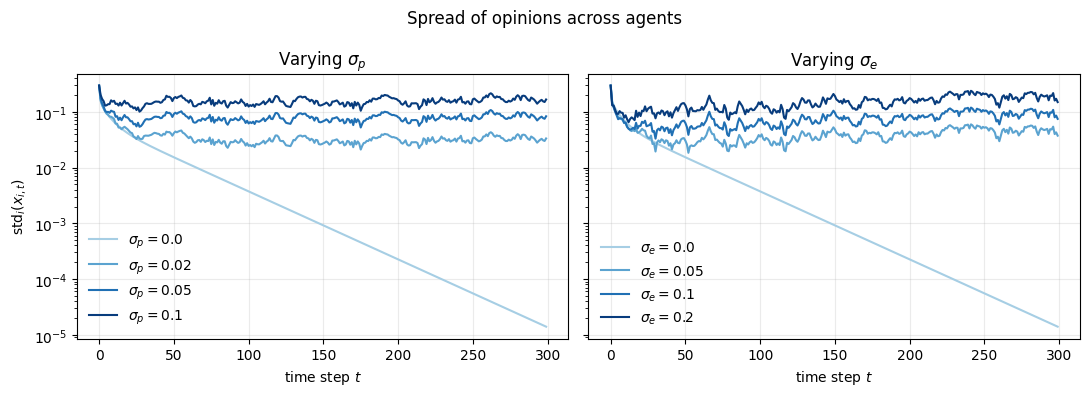

process_noise_sd = 0.0    mean std (last 100 steps) = 7.655e-05
process_noise_sd = 0.02   mean std (last 100 steps) = 3.205e-02
process_noise_sd = 0.05   mean std (last 100 steps) = 8.010e-02
process_noise_sd = 0.1    mean std (last 100 steps) = 1.602e-01
expression_noise_sd = 0.0    mean std (last 100 steps) = 7.655e-05
expression_noise_sd = 0.05   mean std (last 100 steps) = 4.680e-02
expression_noise_sd = 0.1    mean std (last 100 steps) = 9.355e-02
expression_noise_sd = 0.2    mean std (last 100 steps) = 1.870e-01


In [4]:
n_steps_noise = 300
noise_levels = {
    "process_noise_sd": [0.0, 0.02, 0.05, 0.1],
    "expression_noise_sd": [0.0, 0.05, 0.1, 0.2],
}
noise_symbol = {"process_noise_sd": r"\sigma_p", "expression_noise_sd": r"\sigma_e"}

# Std of opinions across agents at each time step, for every (noise source, level).
opinion_spread = {}
for noise_name, levels in noise_levels.items():
    for noise_sd in levels:
        noisy_params = replace(
            model_params, **{"process_noise_sd": 0.0, "expression_noise_sd": 0.0, noise_name: noise_sd}
        )
        opinions, _ = simulate_opinions(
            noisy_params, influence_matrix, initial_opinions, n_steps_noise, np.random.default_rng(0)
        )
        opinion_spread[noise_name, noise_sd] = opinions.std(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (noise_name, levels) in zip(axes, noise_levels.items()):
    line_colors = plt.colormaps["Blues"](np.linspace(0.35, 0.95, len(levels)))
    for line_color, noise_sd in zip(line_colors, levels):
        ax.plot(opinion_spread[noise_name, noise_sd], color=line_color, linewidth=1.5,
                label=rf"${noise_symbol[noise_name]} = {noise_sd}$")
    ax.set_yscale("log")
    ax.set_xlabel(r"time step $t$")
    ax.set_title(rf"Varying ${noise_symbol[noise_name]}$")
    ax.legend(frameon=False)
    ax.grid(alpha=0.25)
axes[0].set_ylabel(r"$\mathrm{std}_i(x_{i,t})$")
fig.suptitle("Spread of opinions across agents")
fig.tight_layout()
plt.show()

for noise_name, levels in noise_levels.items():
    late_spreads = [opinion_spread[noise_name, noise_sd][-100:].mean() for noise_sd in levels]
    for noise_sd, late_spread in zip(levels, late_spreads):
        print(f"{noise_name} = {noise_sd:<5}  mean std (last 100 steps) = {late_spread:.3e}")
    assert np.all(np.diff(late_spreads) > 0), f"spread does not increase with {noise_name}"

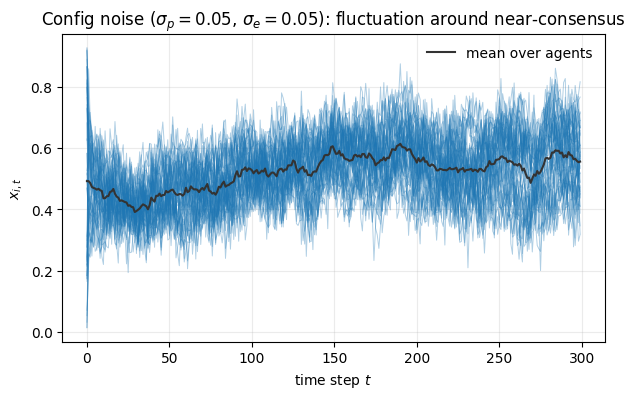

In [5]:
config_noise_opinions, _ = simulate_opinions(
    model_params, influence_matrix, initial_opinions, n_steps_noise, np.random.default_rng(0)
)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(config_noise_opinions, color="C0", linewidth=0.7, alpha=0.35)
ax.plot(config_noise_opinions.mean(axis=1), color="0.2", linewidth=1.5, label=r"mean over agents")
ax.set_xlabel(r"time step $t$")
ax.set_ylabel(r"$x_{i,t}$")
ax.set_title(rf"Config noise ($\sigma_p = {model_params.process_noise_sd}$, "
             rf"$\sigma_e = {model_params.expression_noise_sd}$): fluctuation around near-consensus")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
plt.show()

## Check 3 — Reproducibility

All randomness flows through the `rng` passed in. Two runs with the same seed must give
bit-identical trajectories; a different seed must give different ones.

In [6]:
def run_with_seed(seed):
    return simulate_opinions(model_params, influence_matrix, initial_opinions, n_steps_noise,
                             np.random.default_rng(seed))


opinions_first, expressions_first = run_with_seed(0)
opinions_repeat, expressions_repeat = run_with_seed(0)
opinions_other_seed, expressions_other_seed = run_with_seed(1)

same_seed_identical = (np.array_equal(opinions_first, opinions_repeat)
                       and np.array_equal(expressions_first, expressions_repeat))
other_seed_different = not (np.array_equal(opinions_first, opinions_other_seed)
                            or np.array_equal(expressions_first, expressions_other_seed))
print(f"seed 0 vs seed 0: {'identical' if same_seed_identical else 'different'}")
print(f"seed 0 vs seed 1: {'different' if other_seed_different else 'identical'}")
assert same_seed_identical
assert other_seed_different

seed 0 vs seed 0: identical
seed 0 vs seed 1: different


## Simulator checks

`src/simulate.py` draws $x_0 \sim \mathcal N(\mu_0, \sigma_0^2 I)$ and then runs the
opinion → expression → observation chain for $T$ steps, using separate random streams for the
network and the data. These checks confirm that it produces the right shapes and noise levels,
agrees exactly with `model.py`, draws new datasets on a fixed network, and survives a save/load
round trip.

In [7]:
import tempfile

from src import simulate

ARRAY_NAMES = ("x", "s", "y", "P", "W")   # keys of a simulated dataset
baseline_data = simulate.simulate(config)
n_steps = config.simulation.T

### a. Shapes and initial opinions

Every array is $(T, n)$. The mean and spread of $x_0$ across the $n$ agents should be close to
$\mu_0$ and $\sigma_0$ (with $n = 50$ the sample mean has standard error $\sigma_0/\sqrt{n} \approx 0.03$).

In [8]:
for array_name in ("x", "s", "y", "P"):
    print(f"{array_name}: {baseline_data[array_name].shape}")
    assert baseline_data[array_name].shape == (n_steps, n_agents)
assert baseline_data["W"].shape == (n_agents, n_agents)

initial = baseline_data["x"][0]
print(f"x[0]: mean = {initial.mean():.3f} (μ_0 = {config.simulation.x0_mean}), "
      f"std = {initial.std(ddof=1):.3f} (σ_0 = {config.simulation.x0_sd})")

x: (100, 50)
s: (100, 50)
y: (100, 50)
P: (100, 50)
x[0]: mean = 0.492 (μ_0 = 0.5), std = 0.223 (σ_0 = 0.2)


### b. Noise layers

$s - x = \xi$ and $y - s = e$, so their empirical standard deviations over all $T n = 5000$
entries should match $\sigma_e$ and $\sigma_m$ to within 10% (the sampling error is about 1%).

In [9]:
expression_noise_estimate = np.std(baseline_data["s"] - baseline_data["x"])
measurement_noise_estimate = np.nanstd(baseline_data["y"] - baseline_data["s"])
print(f"std(s − x) = {expression_noise_estimate:.4f}  (σ_e = {model_params.expression_noise_sd})")
print(f"std(y − s) = {measurement_noise_estimate:.4f}  (σ_m = {model_params.measurement_noise_sd})")
assert abs(expression_noise_estimate / model_params.expression_noise_sd - 1) < 0.10
assert abs(measurement_noise_estimate / model_params.measurement_noise_sd - 1) < 0.10

std(s − x) = 0.0497  (σ_e = 0.05)
std(y − s) = 0.1002  (σ_m = 0.1)


### c. Consistency with `model.py`

With every noise level set to zero, $s = x = y$ and the simulator must reproduce
$x_t = A^t x_0$ with $A = \lambda I + (1-\lambda) W$ to rounding error. The data stream draws
$x_0$ first, so the noise-free run starts from the same $x_0$ as the noisy one.

In [10]:
noise_free_config = replace(config, model=replace(
    config.model, process_noise_sd=0.0, expression_noise_sd=0.0, measurement_noise_sd=0.0
))
noise_free_data = simulate.simulate(noise_free_config)
assert np.array_equal(noise_free_data["x"][0], baseline_data["x"][0])   # same x0

self_weight = noise_free_config.model.self_weight
update_matrix = self_weight * np.eye(n_agents) + (1 - self_weight) * noise_free_data["W"]
expected_opinions = np.empty_like(noise_free_data["x"])
expected_opinions[0] = noise_free_data["x"][0]
for t in range(1, n_steps):
    expected_opinions[t] = update_matrix @ expected_opinions[t - 1]

max_error = np.max(np.abs(noise_free_data["x"] - expected_opinions))
print(f"max |x_t − A^t x_0| = {max_error:.2e}")
assert max_error < 1e-10
assert np.array_equal(noise_free_data["s"], noise_free_data["x"])
assert np.array_equal(noise_free_data["y"], noise_free_data["x"])

max |x_t − A^t x_0| = 7.77e-16


### d. Replicates

Passing the same $W$ with fresh data streams (seeds 1 and 2) must keep the network and change
the data. Calling `simulate(config)` twice must give identical results.

In [11]:
shared_network = baseline_data["W"]
replicate_seed1 = simulate.simulate(config, W=shared_network, rng=np.random.default_rng(1))
replicate_seed2 = simulate.simulate(config, W=shared_network, rng=np.random.default_rng(2))

network_unchanged = (np.array_equal(replicate_seed1["W"], shared_network)
                     and np.array_equal(replicate_seed2["W"], shared_network))
opinions_differ = not np.array_equal(replicate_seed1["x"], replicate_seed2["x"])
print(f"same W, seeds 1 vs 2: W {'identical' if network_unchanged else 'different'}, "
      f"x {'different' if opinions_differ else 'identical'}")
assert network_unchanged and opinions_differ
assert replicate_seed1["graph"] is None and replicate_seed2["graph"] is None

repeat_data = simulate.simulate(config)
runs_identical = all(
    np.array_equal(baseline_data[name], repeat_data[name], equal_nan=(name == "y")) for name in ARRAY_NAMES
)
print(f"simulate(config) twice: {'identical' if runs_identical else 'different'}")
assert runs_identical

same W, seeds 1 vs 2: W identical, x different
simulate(config) twice: identical


### e. Save/load round trip

Write to a temporary directory and read back: arrays and config must match exactly.

In [12]:
with tempfile.TemporaryDirectory() as temp_dir:
    save_path = Path(temp_dir) / "results" / "degroot_check"
    simulate.save_simulation(baseline_data, config, save_path)
    loaded_data, loaded_config = simulate.load_simulation(save_path)
    print("written:", sorted(file.name for file in save_path.parent.iterdir()))

for array_name in ARRAY_NAMES:
    assert np.array_equal(baseline_data[array_name], loaded_data[array_name],
                          equal_nan=(array_name == "y")), array_name
assert loaded_config == config
assert set(loaded_data["graph"].edges) == set(baseline_data["graph"].edges)
print("arrays, config and graph edges: identical after round trip")

written: ['degroot_check.npz', 'degroot_check.yaml']
arrays, config and graph edges: identical after round trip


### f. Hidden opinions and observations

Hidden opinions $x_{i,t}$ for all agents, with the noisy observations $y_{i,t}$ of three agents.
The observations scatter around their agent's hidden path with spread
$\sqrt{\sigma_e^2 + \sigma_m^2}$.

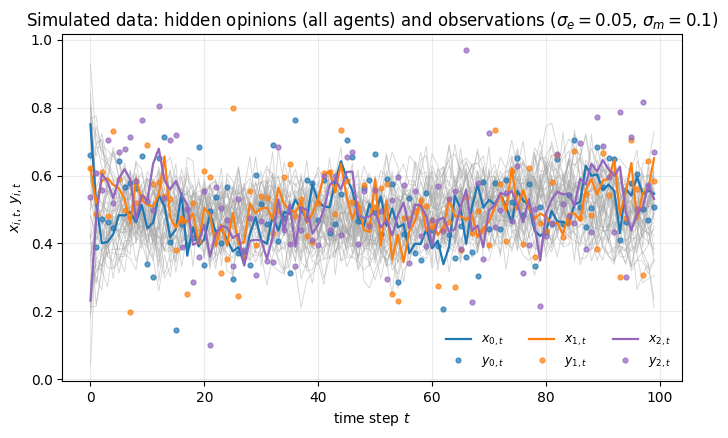

In [13]:
time_steps = np.arange(n_steps)
highlighted_agents = [0, 1, 2]
agent_colors = ["C0", "C1", "C4"]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(time_steps, baseline_data["x"], color="0.65", linewidth=0.6, alpha=0.5)
for agent, agent_color in zip(highlighted_agents, agent_colors):
    ax.plot(time_steps, baseline_data["x"][:, agent], color=agent_color, linewidth=1.6,
            label=rf"$x_{{{agent},t}}$")
    ax.plot(time_steps, baseline_data["y"][:, agent], "o", color=agent_color, markersize=3.5, alpha=0.7,
            label=rf"$y_{{{agent},t}}$")
ax.set_xlabel(r"time step $t$")
ax.set_ylabel(r"$x_{i,t}$, $y_{i,t}$")
ax.set_title(rf"Simulated data: hidden opinions (all agents) and observations "
             rf"($\sigma_e = {model_params.expression_noise_sd}$, "
             rf"$\sigma_m = {model_params.measurement_noise_sd}$)")
ax.legend(frameon=False, ncol=3, fontsize=9)
ax.grid(alpha=0.25)
plt.show()

## Kalman filter checks

For DeGroot with continuous observations the model is linear-Gaussian. With the augmented state
$z_t = [x_t; s_t]$,

$$
z_t = F z_{t-1} + w_t,\quad w_t \sim \mathcal N(0, Q), \qquad Y_t = H z_t + e_t,\quad e_t \sim \mathcal N(0, \sigma_m^2 I),
$$

so `src/kalman.py` computes the exact log-likelihood $\log p(Y \mid \lambda, \sigma_p, \sigma_e)$.
This is the reference the particle filter must match. The checks confirm it is exact, that it
peaks near the true parameters, and that its filtered opinions are closer to the truth than the
raw observations.

In [14]:
from src import kalman

### a. Kalman vs. brute force

On a tiny problem ($n = 3$ agents on a ring, $T = 5$) the stacked vector $(Y_0, \dots, Y_{T-1})$
is a single 15-dimensional Gaussian whose mean and covariance can be written down directly.
Its log-density must equal the Kalman log-likelihood to rounding error. Three cases:

- the baseline noise levels;
- $\sigma_e = 0$, where $Q$ is singular (the filter must still work because $R$ is positive definite);
- missing posts (`NaN`), including one time step with no posts at all. The brute force handles them by
  dropping those entries, which is exactly marginalising them out.

In [15]:
tiny_config = replace(
    config,
    network=replace(config.network, n_agents=3, k=2, p=0.0),
    simulation=replace(config.simulation, T=5),
)
no_expression_noise_config = replace(tiny_config, model=replace(tiny_config.model, expression_noise_sd=0.0))

for case_name, case_config in [("baseline noise", tiny_config), ("σ_e = 0", no_expression_noise_config)]:
    tiny_data = simulate.simulate(case_config)
    observations_with_gaps = tiny_data["y"].copy()
    observations_with_gaps[1, 0] = np.nan      # one missing post
    observations_with_gaps[3, :] = np.nan      # a time step with no posts

    for gap_label, observations in [("all posts", tiny_data["y"]), ("with NaN", observations_with_gaps)]:
        kalman_value = kalman.kalman_loglik(observations, tiny_data["W"], case_config.model, case_config.simulation)
        brute_force_value = kalman.brute_force_loglik(
            observations, tiny_data["W"], case_config.model, case_config.simulation
        )
        difference = abs(kalman_value - brute_force_value)
        print(f"{case_name:<15} {gap_label:<10} kalman = {kalman_value:+.10f}  "
              f"brute force = {brute_force_value:+.10f}  |diff| = {difference:.1e}")
        assert np.isfinite(kalman_value)
        assert difference < 1e-8

baseline noise  all posts  kalman = +2.2757555364  brute force = +2.2757555364  |diff| = 5.3e-15
baseline noise  with NaN   kalman = -0.4039723234  brute force = -0.4039723234  |diff| = 1.6e-15
σ_e = 0         all posts  kalman = +7.2595115599  brute force = +7.2595115599  |diff| = 1.8e-15
σ_e = 0         with NaN   kalman = +4.3212638112  brute force = +4.3212638112  |diff| = 5.3e-15


### b. Likelihood profiles

On the baseline dataset ($n = 50$, $T = 100$) we vary one parameter at a time over a grid, keeping
the others at their true values. The profile of $\lambda$ should peak within one grid step of the
truth. For $\sigma_p$ and $\sigma_e$ we only report the peak: with $\sigma_m$ fixed, $\sigma_e$ is the
harder one to pin down (an identifiability question in the plan).

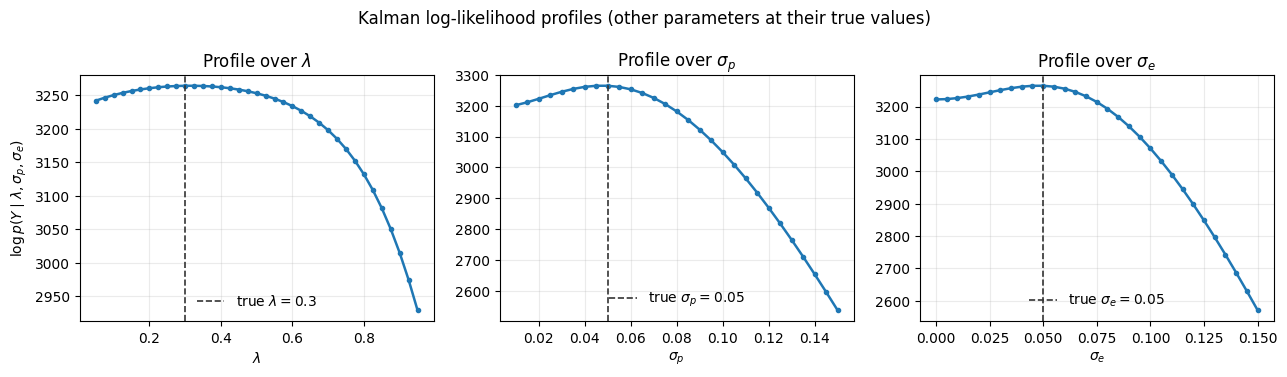

self_weight          argmax = 0.3250  true = 0.3  (grid step 0.0250, 1.0 steps away)
process_noise_sd     argmax = 0.0500  true = 0.05  (grid step 0.0050, 0.0 steps away)
expression_noise_sd  argmax = 0.0500  true = 0.05  (grid step 0.0050, 0.0 steps away)


In [16]:
profile_grids = {
    "self_weight": np.linspace(0.05, 0.95, 37),
    "process_noise_sd": np.linspace(0.01, 0.15, 29),
    "expression_noise_sd": np.linspace(0.0, 0.15, 31),
}
parameter_symbol = {"self_weight": r"\lambda", "process_noise_sd": r"\sigma_p", "expression_noise_sd": r"\sigma_e"}

profile_logliks = {}
for parameter_name, grid in profile_grids.items():
    profile_logliks[parameter_name] = np.array([
        kalman.kalman_loglik(baseline_data["y"], baseline_data["W"],
                             replace(model_params, **{parameter_name: value}), config.simulation)
        for value in grid
    ])

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (parameter_name, grid) in zip(axes, profile_grids.items()):
    true_value = getattr(model_params, parameter_name)
    symbol = parameter_symbol[parameter_name]
    ax.plot(grid, profile_logliks[parameter_name], color="C0", linewidth=1.8, marker="o", markersize=3)
    ax.axvline(true_value, color="0.2", linestyle="--", linewidth=1.2, label=rf"true ${symbol} = {true_value}$")
    ax.set_xlabel(rf"${symbol}$")
    ax.set_title(rf"Profile over ${symbol}$")
    ax.legend(frameon=False, loc="lower center")
    ax.grid(alpha=0.25)
axes[0].set_ylabel(r"$\log p(Y \mid \lambda, \sigma_p, \sigma_e)$")
fig.suptitle("Kalman log-likelihood profiles (other parameters at their true values)")
fig.tight_layout()
plt.show()

for parameter_name, grid in profile_grids.items():
    true_value = getattr(model_params, parameter_name)
    best_value = grid[np.argmax(profile_logliks[parameter_name])]
    grid_step = grid[1] - grid[0]
    print(f"{parameter_name:<20} argmax = {best_value:.4f}  true = {true_value}  "
          f"(grid step {grid_step:.4f}, {abs(best_value - true_value) / grid_step:.1f} steps away)")

self_weight_grid = profile_grids["self_weight"]
best_self_weight = self_weight_grid[np.argmax(profile_logliks["self_weight"])]
assert abs(best_self_weight - model_params.self_weight) <= (self_weight_grid[1] - self_weight_grid[0]) + 1e-12

### c. Filtered opinions

The filtered mean $\mathbb E[x_t \mid Y_{0:t}]$ combines each agent's own posts with its
neighbours' posts and the dynamics, so it should track the hidden opinion more closely than the raw
observation $Y_t$, whose error has standard deviation $\sqrt{\sigma_e^2 + \sigma_m^2}$.

RMSE(filtered x, true x) = 0.0522
RMSE(Y, true x)          = 0.1123   (theory √(σ_e² + σ_m²) = 0.1118)


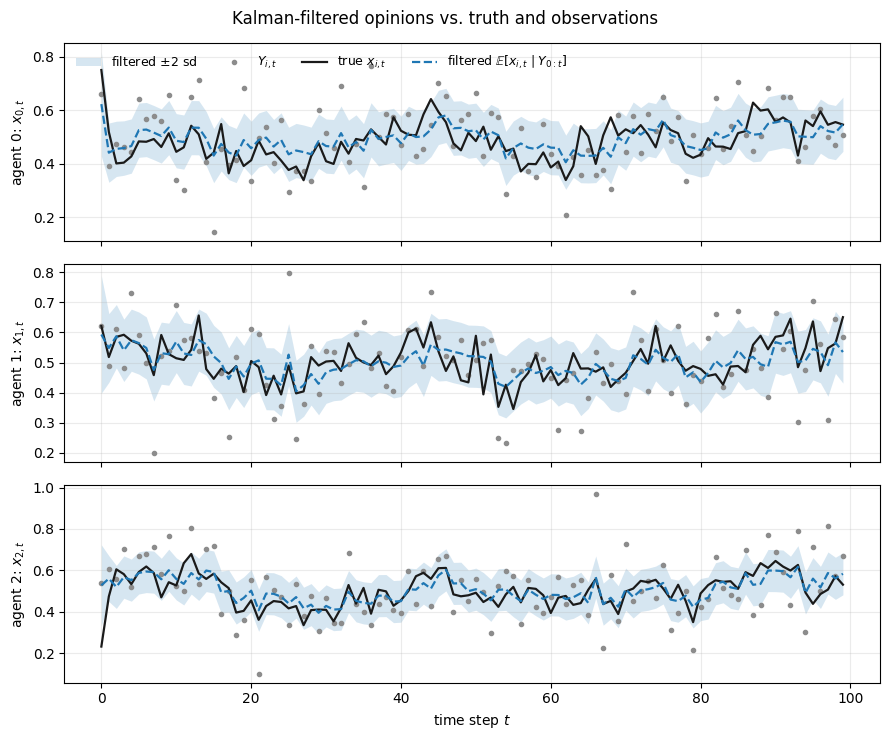

In [17]:
_, filtered_means, filtered_covs = kalman.kalman_loglik(
    baseline_data["y"], baseline_data["W"], model_params, config.simulation, return_filtered=True
)
filtered_opinions = filtered_means[:, :n_agents]
filtered_opinion_sd = np.sqrt(np.diagonal(filtered_covs, axis1=1, axis2=2)[:, :n_agents])
true_opinions = baseline_data["x"]

rmse_filtered = np.sqrt(np.mean((filtered_opinions - true_opinions) ** 2))
rmse_observations = np.sqrt(np.nanmean((baseline_data["y"] - true_opinions) ** 2))
print(f"RMSE(filtered x, true x) = {rmse_filtered:.4f}")
print(f"RMSE(Y, true x)          = {rmse_observations:.4f}   "
      f"(theory √(σ_e² + σ_m²) = {np.hypot(model_params.expression_noise_sd, model_params.measurement_noise_sd):.4f})")
assert rmse_filtered < rmse_observations

time_steps = np.arange(n_steps)
fig, axes = plt.subplots(3, 1, figsize=(9, 7.5), sharex=True)
for ax, agent in zip(axes, highlighted_agents):
    ax.fill_between(time_steps,
                    filtered_opinions[:, agent] - 2 * filtered_opinion_sd[:, agent],
                    filtered_opinions[:, agent] + 2 * filtered_opinion_sd[:, agent],
                    color="C0", alpha=0.18, linewidth=0, label=r"filtered $\pm 2$ sd")
    ax.plot(time_steps, baseline_data["y"][:, agent], "o", color="0.55", markersize=3, label=r"$Y_{i,t}$")
    ax.plot(time_steps, true_opinions[:, agent], color="0.1", linewidth=1.6, label=r"true $x_{i,t}$")
    ax.plot(time_steps, filtered_opinions[:, agent], color="C0", linewidth=1.6, linestyle="--",
            label=r"filtered $\mathbb{E}[x_{i,t} \mid Y_{0:t}]$")
    ax.set_ylabel(rf"agent {agent}: $x_{{{agent},t}}$")
    ax.grid(alpha=0.25)
axes[0].legend(frameon=False, ncol=4, fontsize=9, loc="upper left")
axes[-1].set_xlabel(r"time step $t$")
fig.suptitle("Kalman-filtered opinions vs. truth and observations")
fig.tight_layout()
plt.show()